# What Gojek users complain about

225,002 Google Play reviews of the Gojek app, written between November 2021 and February 2024. The notebook looks at how ratings moved over that period, sorts 1-2 star reviews into complaint themes, and checks which app releases drew the most negative reviews.

Reviewer names are dropped on load. Only the review text, star rating, timestamp and app version are used.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import chart_style as cs
from themes import THEMES, tag_themes

cs.apply()
IMAGES = ROOT / "images"
RESULTS = ROOT / "results"
SOURCE = "Source: Gojek App Reviews Bahasa Indonesia (Kaggle), Google Play reviews Nov 2021 - Feb 2024."
pd.set_option("display.max_colwidth", 120)

In [2]:
reviews = (
    pd.read_csv(ROOT / "data/raw/GojekAppReviewV4.0.0-V4.9.3_Cleaned.csv", parse_dates=["at"])
    .drop(columns="userName")
    .rename(columns={"content": "text", "score": "rating", "at": "posted_at", "appVersion": "version"})
)
reviews["negative"] = reviews["rating"] <= 2
reviews["month"] = reviews["posted_at"].dt.to_period("M").dt.to_timestamp()

print(f"{len(reviews):,} reviews, {reviews['posted_at'].min():%d %b %Y} to {reviews['posted_at'].max():%d %b %Y}")
reviews["rating"].value_counts(normalize=True).sort_index().mul(100).round(1).rename("% of reviews").to_frame()

225,002 reviews, 05 Nov 2021 to 02 Feb 2024


,% of reviews
rating,
1,20.1
2,4.0
3,4.2
4,6.4
5,65.4


## Ratings over time

Monthly average rating and the share of 1-2 star reviews. February 2024 has only a few days of data and is left out.

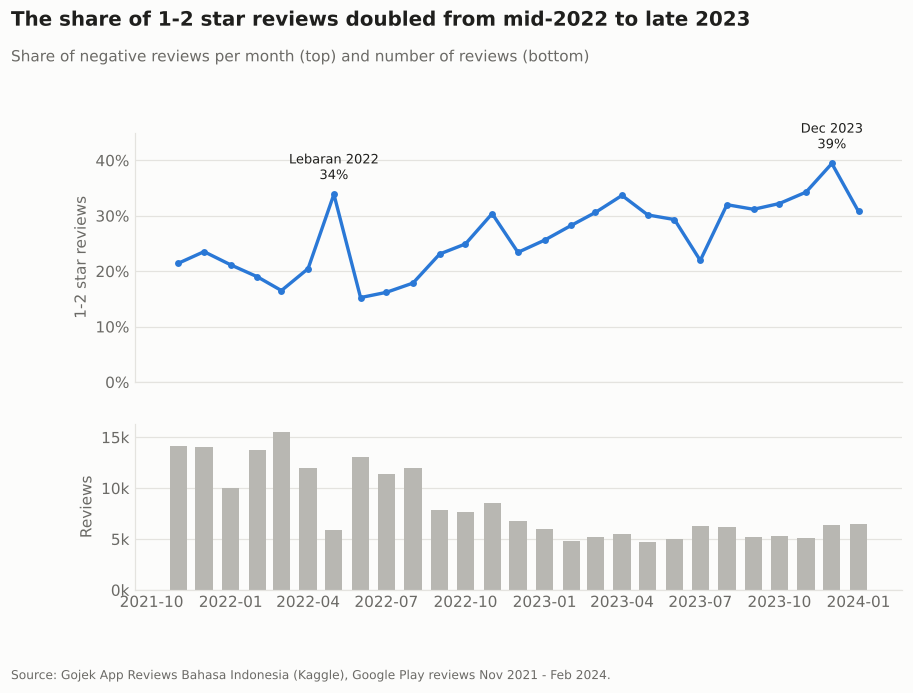

In [3]:
monthly = (
    reviews[reviews["month"] < "2024-02-01"]
    .groupby("month")
    .agg(reviews=("rating", "size"), avg_rating=("rating", "mean"), negative_share=("negative", "mean"))
)
monthly.to_csv(RESULTS / "monthly_ratings.csv")

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True,
                                  gridspec_kw={"height_ratios": [1.5, 1], "hspace": 0.2})
top.plot(monthly.index, monthly["negative_share"] * 100, color=cs.SERIES[0], lw=2.2, marker="o", ms=3.5)
top.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
top.set_ylim(0, 45)
top.set_ylabel("1-2 star reviews")
for label, date in [("Lebaran 2022", "2022-05-01"), ("Dec 2023", "2023-12-01")]:
    value = monthly.loc[date, "negative_share"] * 100
    top.annotate(f"{label}\n{value:.0f}%", (pd.Timestamp(date), value), xytext=(0, 10),
                 textcoords="offset points", ha="center", fontsize=8.5, color=cs.INK)
bottom.bar(monthly.index, monthly["reviews"], width=20, color=cs.NEUTRAL)
bottom.set_ylabel("Reviews")
bottom.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
cs.titles(fig, "The share of 1-2 star reviews doubled from mid-2022 to late 2023",
          "Share of negative reviews per month (top) and number of reviews (bottom)", SOURCE)
cs.save(fig, IMAGES / "01_monthly_ratings.png")
fig

In [4]:
first, last = monthly.loc["2022-06-01":"2022-08-01"], monthly.loc["2023-10-01":"2024-01-01"]
print(f"Jun-Aug 2022: {first['negative_share'].mean():.1%} negative, average rating {first['avg_rating'].mean():.2f}")
print(f"Oct 2023-Jan 2024: {last['negative_share'].mean():.1%} negative, average rating {last['avg_rating'].mean():.2f}")

Jun-Aug 2022: 16.4% negative, average rating 4.23
Oct 2023-Jan 2024: 34.2% negative, average rating 3.53


## What the negative reviews are about

Each 1-2 star review is matched against ten keyword themes (see `src/themes.py`). The word lists were built from the most frequent words and word pairs in negative reviews, including slang and common misspellings. A review can belong to several themes; reviews that only say the app is bad without saying why match none.

In [5]:
negative = reviews[reviews["negative"]].copy()
negative_themes = tag_themes(negative["text"])

coverage = negative_themes.any(axis=1).mean()
print(f"{len(negative):,} negative reviews, {coverage:.0%} match at least one theme")

theme_share = negative_themes.mean().sort_values()
theme_share.mul(100).round(1).rename("% of negative reviews").sort_values(ascending=False).to_frame()

54,171 negative reviews, 69% match at least one theme


,% of negative reviews
GoPay and balance,20.9
App bugs and speed,16.3
Prices and fees,11.7
Account and login,11.5
GoFood orders,11.3
Promos and vouchers,10.8
Finding a driver,8.5
Customer service,6.8
Maps and addresses,4.6
Driver conduct,2.2


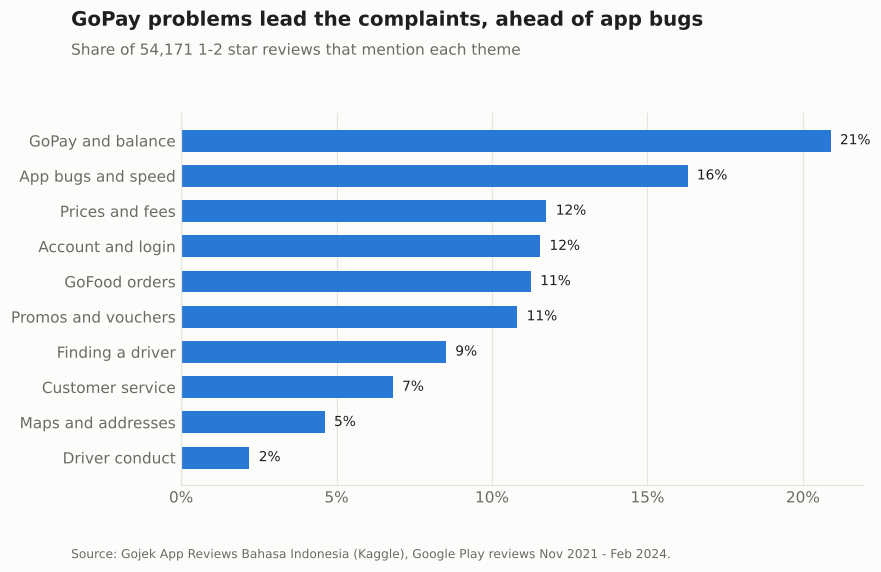

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(theme_share.index, theme_share * 100, color=cs.SERIES[0], height=0.62)
for y, v in enumerate(theme_share * 100):
    ax.text(v + 0.3, y, f"{v:.0f}%", va="center", fontsize=9, color=cs.INK)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.xaxis.set_major_locator(mtick.MultipleLocator(5))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
cs.titles(fig, "GoPay problems lead the complaints, ahead of app bugs",
          f"Share of {len(negative):,} 1-2 star reviews that mention each theme", SOURCE)
cs.save(fig, IMAGES / "02_complaint_themes.png")
fig

## How the themes moved

Share of each quarter's negative reviews per theme, for the six largest themes. The first quarter starts in November 2021 and the last one has a single month.

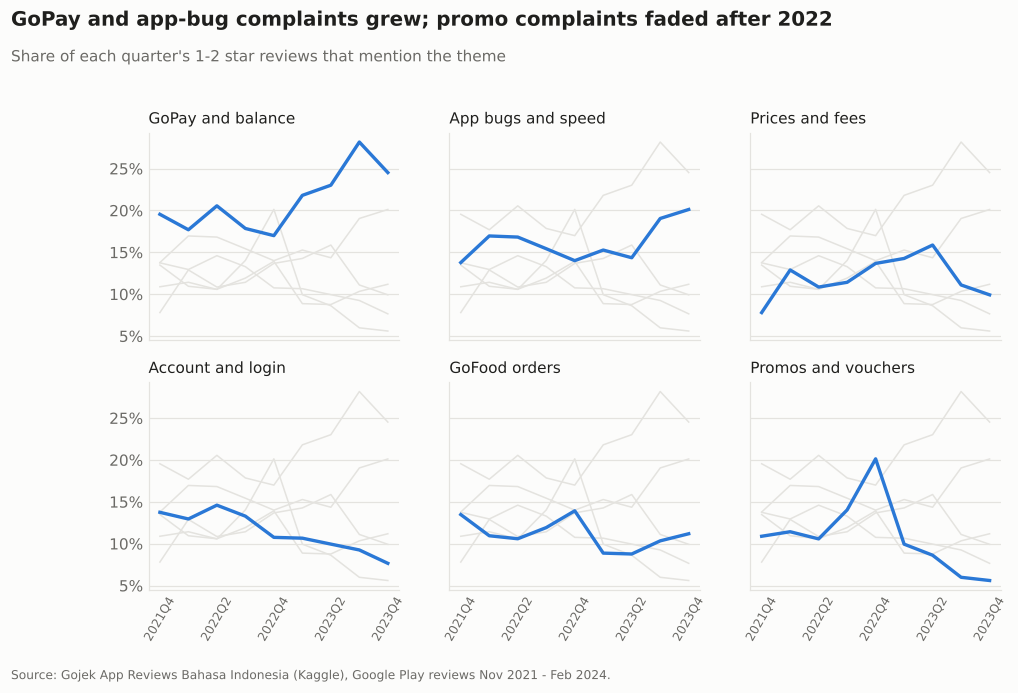

In [7]:
negative["quarter"] = negative["posted_at"].dt.to_period("Q")
quarterly = negative_themes.groupby(negative["quarter"]).mean().mul(100)
quarterly = quarterly[quarterly.index < pd.Period("2024Q1")]
quarterly.round(1).rename_axis("quarter").to_csv(RESULTS / "theme_share_by_quarter.csv")

top_themes = theme_share.sort_values(ascending=False).index[:6]
labels = [str(q) for q in quarterly.index]
fig, axes = plt.subplots(2, 3, figsize=(10, 5.4), sharex=True, sharey=True)
for ax, theme in zip(axes.flat, top_themes):
    for other in top_themes:
        ax.plot(labels, quarterly[other], color=cs.GRID, lw=1)
    ax.plot(labels, quarterly[theme], color=cs.SERIES[0], lw=2.2)
    ax.set_title(theme, loc="left", fontsize=10, color=cs.INK)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.tick_params(axis="x", rotation=60, labelsize=8)
    ax.set_xticks(range(0, len(labels), 2), labels[::2])
cs.titles(fig, "GoPay and app-bug complaints grew; promo complaints faded after 2022",
          "Share of each quarter's 1-2 star reviews that mention the theme", SOURCE)
cs.save(fig, IMAGES / "03_theme_trends.png")
fig

In [8]:
quarterly.loc[:, top_themes].round(1).T

quarter,2021Q4,2022Q1,2022Q2,2022Q3,2022Q4,2023Q1,2023Q2,2023Q3,2023Q4
GoPay and balance,19.5,17.7,20.6,17.8,17.0,21.8,23.0,28.2,24.5
App bugs and speed,13.8,17.0,16.8,15.4,14.0,15.3,14.4,19.0,20.1
Prices and fees,7.8,12.9,10.9,11.4,13.7,14.3,15.9,11.1,9.9
Account and login,13.7,12.9,14.6,13.3,10.8,10.7,9.9,9.2,7.7
GoFood orders,13.5,10.9,10.6,11.9,13.9,8.9,8.8,10.3,11.2
Promos and vouchers,10.9,11.4,10.6,14.0,20.1,9.9,8.6,6.0,5.6


## Which themes go with the lowest ratings

A theme can be frequent without being severe. Promos, for example, also appear in happy reviews ("promonya banyak"). Below, for every review that mentions a theme, the share that gave 1-2 stars, against the 24% baseline across all reviews.

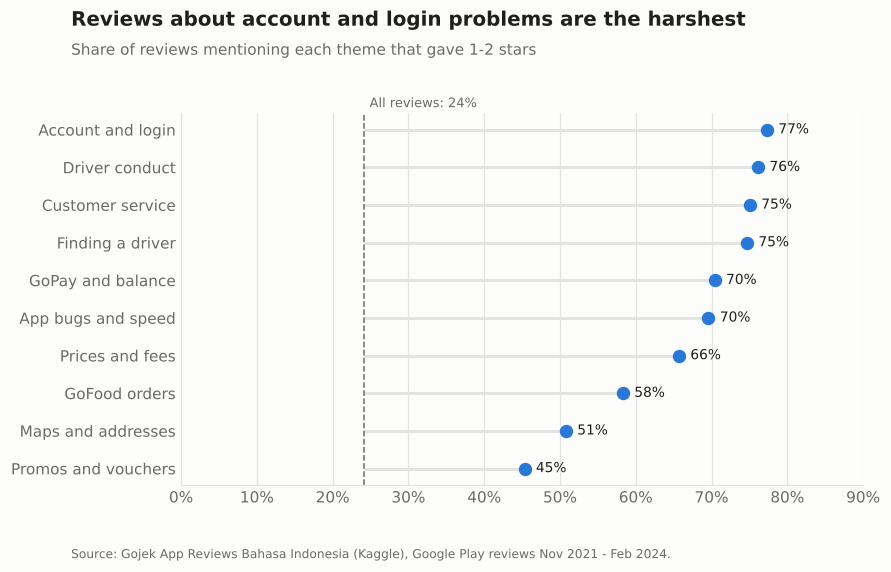

In [9]:
all_themes = tag_themes(reviews["text"])
severity = pd.DataFrame({
    "reviews_mentioning": all_themes.sum(),
    "negative_share": [reviews.loc[all_themes[t], "negative"].mean() for t in all_themes],
    "avg_rating": [reviews.loc[all_themes[t], "rating"].mean() for t in all_themes],
}).sort_values("negative_share").rename_axis("theme")
severity.round(3).to_csv(RESULTS / "theme_severity.csv")
baseline = reviews["negative"].mean()

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.hlines(severity.index, baseline * 100, severity["negative_share"] * 100, color=cs.GRID, lw=2)
ax.scatter(severity["negative_share"] * 100, severity.index, color=cs.SERIES[0], s=60, zorder=3)
ax.axvline(baseline * 100, color=cs.MUTED, lw=1, ls="--")
ax.text(baseline * 100 + 0.8, len(severity) - 0.4, f"All reviews: {baseline:.0%}", fontsize=8.5, color=cs.MUTED)
for y, v in enumerate(severity["negative_share"] * 100):
    ax.text(v + 1.5, y, f"{v:.0f}%", va="center", fontsize=9, color=cs.INK)
ax.set_xlim(0, 90)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
cs.titles(fig, "Reviews about account and login problems are the harshest",
          "Share of reviews mentioning each theme that gave 1-2 stars", SOURCE)
cs.save(fig, IMAGES / "04_theme_severity.png")
fig

## App releases

Versions with at least 2,000 reviews, in release order. Reviews are attributed to the version the reviewer had installed, so a version also collects complaints about problems that are not in the app itself (fees, drivers).

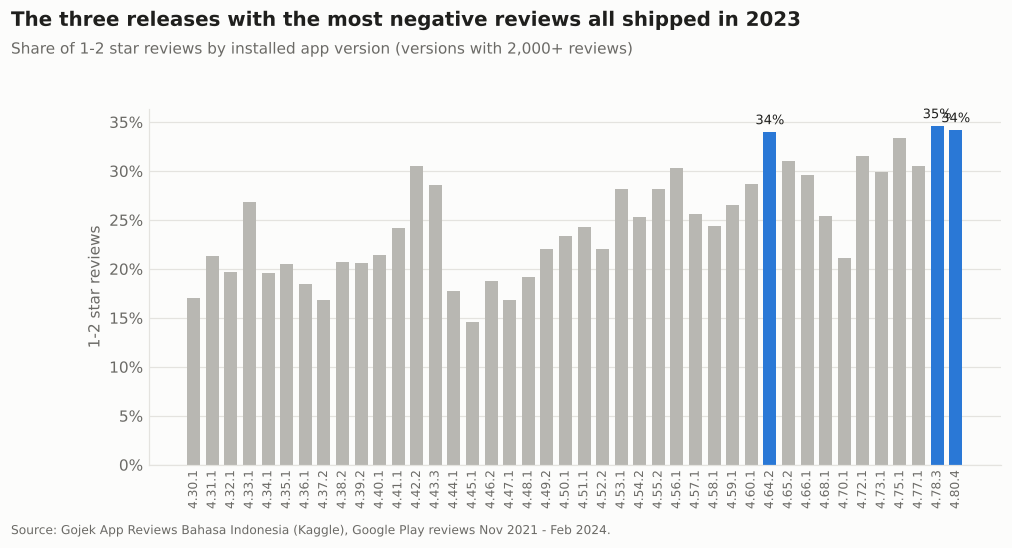

In [10]:
def version_key(v: str) -> tuple[int, ...]:
    return tuple(int(part) for part in v.split("."))

by_version = (
    reviews.groupby("version")
    .agg(reviews=("rating", "size"), negative_share=("negative", "mean"), first_seen=("posted_at", "min"))
    .query("reviews >= 2000")
)
by_version = by_version.loc[sorted(by_version.index, key=version_key)]
by_version.round({"negative_share": 3}).to_csv(RESULTS / "negative_share_by_version.csv")

worst = by_version["negative_share"].nlargest(3).index
fig, ax = plt.subplots(figsize=(10, 4.2))
colors = [cs.SERIES[0] if v in worst else cs.NEUTRAL for v in by_version.index]
ax.bar(by_version.index, by_version["negative_share"] * 100, color=colors, width=0.7)
for v in worst:
    x = list(by_version.index).index(v)
    ax.text(x, by_version.loc[v, "negative_share"] * 100 + 0.8, f"{by_version.loc[v, 'negative_share']:.0%}",
            ha="center", fontsize=8.5, color=cs.INK)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.set_ylabel("1-2 star reviews")
cs.titles(fig, "The three releases with the most negative reviews all shipped in 2023",
          "Share of 1-2 star reviews by installed app version (versions with 2,000+ reviews)", SOURCE)
cs.save(fig, IMAGES / "05_versions.png")
fig

In [11]:
by_version.loc[worst].assign(first_seen=lambda d: d["first_seen"].dt.date)

,reviews,negative_share,first_seen
version,,,
4.78.3,3500,0.346000,2023-11-08
4.80.4,3913,0.341937,2023-12-20
4.64.2,2145,0.339860,2023-03-24


## In the users' words

Two short negative reviews per theme, picked at random among those under 140 characters.

In [12]:
rng = np.random.default_rng(7)
examples = []
for theme in theme_share.sort_values(ascending=False).index:
    pool = negative.loc[negative_themes[theme] & (negative["text"].str.len() < 140), "text"]
    for text in pool.sample(2, random_state=rng.integers(1_000_000)):
        examples.append({"theme": theme, "review": text})
pd.DataFrame(examples)

,theme,review
0,GoPay and balance,Gopay susah banget buat di pake bayar belanja di mini marketalasanny melebihi bataspadahal terahir pake tgl 8 april
1,GoPay and balance,Hati hati gopay tabungannya menipu
2,App bugs and speed,eror
3,App bugs and speed,Eror Aplikasinya runtuh pas aku masuk eror aplikasinya ini harus diperbaiki pls ya mohon kalau bintang 2
4,Prices and fees,Ini gimana cerita nya ongkir lebih mahal dari harga makanan nya yaa
5,Prices and fees,Biaya aplikasinya kelewat mahal sedangkan aplikasinya sering error buat apal biaya aplikasi mahal kalau kualitas apl...
6,Account and login,Udh bertahun2 pake gojek pesen gofood gk bisa d cancel trs payletter di blokir maaf yaa kali ini saya uninstal ha...
7,Account and login,Aplikasi gx jelasmau masuk ke akun sendiri ajah ribetgx bisa masuk2 alamat gopay gw ilang ini
8,GoFood orders,Promo resto ya promo restovoucher ya voucher emg sama ya promo resto dgn voucher makanya ga bs d gabung lg
9,GoFood orders,Jelek Mau pesen gofood aja susahnya minta ampun ampe berkali2 ga nemu driver


## Summary

- The share of 1-2 star reviews went from about 16% in mid-2022 to about 34% in the last months of 2023, and the average rating fell from about 4.2 to 3.5.
- GoPay (balance, top-ups, PayLater) is the largest complaint theme and grew from about 19% of negative reviews at the end of 2021 to 28% in Q3 2023.
- Account and login issues are less common but the most severe: 77% of reviews that mention them give 1-2 stars.
- Promo complaints peaked in Q4 2022 and dropped by more than half in 2023. App-bug complaints rose in the second half of 2023.
- Price and fee complaints jumped in May 2022, the month of Lebaran.

Limits: themes come from keyword matching, so sarcasm and unusual spellings are missed, and about a third of negative reviews have no specific topic. Play Store reviews come from people motivated to write one and are not a sample of all users.